# 03 · Feature preparation, PCA, and clustering

**Question:** How is the dashboard’s saved 2024 district matrix formed, and what do its verified PCA and clustering artifacts describe?

**Input and scope:** The active analysis pointer selects a saved 2024 run. The notebook verifies its run manifest, feature-input hash, model-artifact hashes, and source dataset hash, then reads the saved points and memberships. It does not fit or overwrite any model.

In [1]:
from pathlib import Path
import csv, hashlib, json, sqlite3, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "analysis/output/runs/current.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("CrimeScope root not found; open from the repo root or notebooks folder. See docs/handoff.md.")
sys.path.insert(0, str(ROOT / "analysis/src"))

def read_json(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required artifact missing: {path}. Restore the analysis handoff described in docs/handoff.md.")
    return json.loads(path.read_text(encoding="utf-8"))

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

release_pointer = read_json(ROOT / "data/serving/current.json")
release = read_json(ROOT / release_pointer["release_path"] / "release_manifest.json")
run_pointer = read_json(ROOT / "analysis/output/runs/current.json")
run_manifest_path = ROOT / run_pointer["manifest"]
run = read_json(run_manifest_path)
run_dir = run_manifest_path.parent
dataset_path = ROOT / release["source_dataset"]["path"]
feature_path = ROOT / run["feature_input"]["path"]
sqlite_path = ROOT / release_pointer["sqlite_path"]
for path, expected, label in [
    (dataset_path, release["source_dataset"]["sha256"], "active canonical dataset"),
    (sqlite_path, release["sqlite"]["sha256"], "active serving SQLite"),
    (feature_path, run["feature_input"]["sha256"], "active feature input"),
]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing {label}: {path}. Restore local handoff files using docs/handoff.md.")
    assert sha256(path) == expected, f"{label} hash mismatch at {path}; restore the matching manifest-selected artifact."
assert run_pointer["run_id"] == run["run_id"]
assert run["dataset"]["sha256"] == release["source_dataset"]["sha256"]
taxonomy = read_json(ROOT / "config/category_hierarchy.json")
db = sqlite3.connect(f"file:{sqlite_path.as_posix()}?mode=ro", uri=True)

def artifact(relative):
    path = run_dir / relative
    expected = run["artifacts"].get(relative)
    if expected is None:
        raise KeyError(f"Active run manifest does not list expected artifact {relative}")
    if not path.is_file():
        raise FileNotFoundError(f"Active run artifact missing: {path}. Restore the active analysis handoff described in docs/handoff.md.")
    assert sha256(path) == expected, f"Saved artifact hash mismatch: {path}"
    return path

print(f"Run: {run['run_id']} | release: {release['release_id']} | saved source hash: {run['dataset']['sha256'][:16]}…")

# --- CrimeScope notebook figure style ---
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PRIMARY = "#237866"
ACCENT = "#d47a43"
BLUE = "#3d7894"
RED = "#b91c1c"
GREY = "#94a3b8"
SERIES = ["#237866", "#6689ba", "#cf9b46", "#9176ae", "#b45309"]

mpl.rcParams.update({
    "figure.figsize": (11, 5),
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.titleweight": "bold",
})


def fig_note(fig, text, y=-0.15):
    fig.text(0.5, y, text, ha="center", fontsize=9, color="#555")


Run: ncrb-national-2024-admin-log1p-zscore-20261107-v4 | release: ncrb-districtwise-2021-2024-ecec48b772bc | saved source hash: ecec48b772bc1725…


## From canonical rows to the 2024 feature input

The active runner selects 2024 rows that are valid, eligible administrative-district observations and whose category roles are `component` or `leaf`. It then requires exactly one value per district/category pair and no null feature values. Official totals and parent totals overlap their component rows, so they are excluded from the feature matrix.

In [2]:
feature_roles = set(taxonomy["pcaFeatureRoles"])
feature_defs = {c["id"]: c for c in taxonomy["categories"]
                if 2024 in c["years"] and set(c["rolesByYear"].get("2024", [])) & feature_roles}
excluded_defs = [c for c in taxonomy["categories"] if 2024 in c["years"]
                 and set(c["rolesByYear"].get("2024", [])) & {"official_total", "parent_total"}]
features = pd.read_csv(feature_path)
assert set(features["year"]) == {2024}
assert set(features["region_type"]) == {"administrative_district"}
assert set(features["quality_status"]) == {"valid"}
assert len(feature_defs) == run["feature_input"]["features"] == 131
assert features["region_id"].nunique() == run["feature_input"]["regions"] == 774
assert features["category_id"].nunique() == 131
assert len(features) == run["feature_input"]["rows"] == 101394
assert set(features["category_id"]) == set(feature_defs)
assert not features.duplicated(["region_id", "category_id"]).any()
assert features["total"].notna().all()

category_ids = list(feature_defs)
placeholders = ",".join("?" for _ in category_ids)
source_rows = db.execute(f"""SELECT count(*) FROM crime_observations
    WHERE year=2024 AND region_type='administrative_district' AND quality_status='valid'
      AND comparison_status='eligible' AND category_id IN ({placeholders})""", category_ids).fetchone()[0]
assert source_rows == len(features)
print(f"Canonical selection: {source_rows:,} rows -> {features.region_id.nunique()} districts x {features.category_id.nunique()} feature categories.")
print(f"Taxonomy roles excluded from the feature set: {len(excluded_defs)} official-total/parent-total categories.")
display(features[["state_name","region_name","year","category","total","quality_status"]].head(8))

Canonical selection: 101,394 rows -> 774 districts x 131 feature categories.
Taxonomy roles excluded from the feature set: 23 official-total/parent-total categories.


,state_name,region_name,year,category,total,quality_status
0,A&N Islands,Nicobar,2024,Obscene acts and songs at public Places,0,valid
1,A&N Islands,Nicobar,2024,ii) K & A of Children,0,valid
2,A&N Islands,Nicobar,2024,e) Voluntarily Causing hurt or Grievous Hurt/A...,0,valid
3,A&N Islands,Nicobar,2024,"Offences related to Mischief,326 BNS/Section 4...",0,valid
4,A&N Islands,Nicobar,2024,Cruelty by Husband or Relatives,0,valid
5,A&N Islands,Nicobar,2024,d) Voluntarily causing hurt or Grievous Hurt b...,1,valid
6,A&N Islands,Nicobar,2024,b) Vehicle TheftBNS),0,valid
7,A&N Islands,Nicobar,2024,Attempt to commit Murder,0,valid


## Feature matrix selection

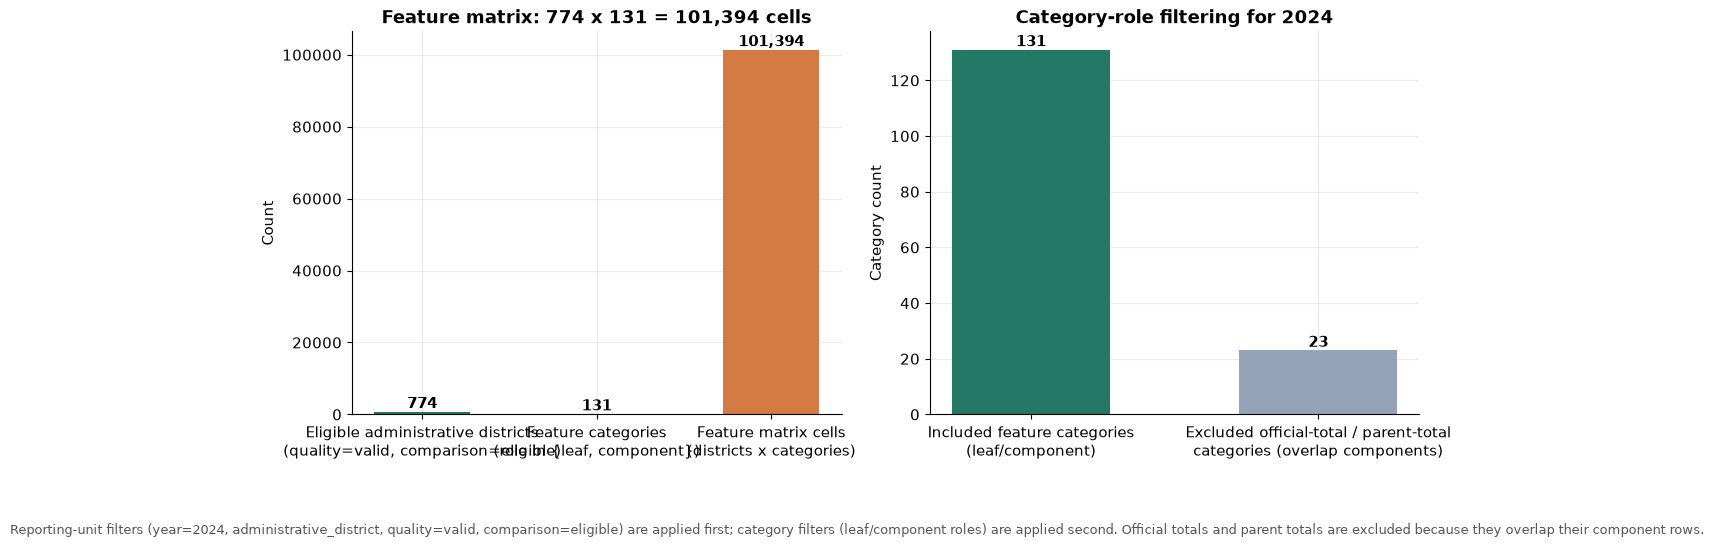

In [3]:

# Figure N03-01 · feature_matrix_selection
# How the active 2024 cohort and category roles produce the 774 x 131 feature matrix.
canon_rows = int(source_rows) if 'source_rows' in globals() else len(features)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
axes[0].bar(["Eligible administrative districts\n(quality=valid, comparison=eligible)",
             "Feature categories\n(role in {leaf, component})",
             "Feature matrix cells\n(districts x categories)"],
            [features["region_id"].nunique(), len(feature_defs), len(features)],
            color=[PRIMARY, BLUE, ACCENT], width=0.55)
for i, v in enumerate([features["region_id"].nunique(), len(feature_defs), len(features)]):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Count")
axes[0].set_title(f"Feature matrix: {features['region_id'].nunique()} x {len(feature_defs)} = {len(features):,} cells")
excluded_n = len(excluded_defs)
axes[1].bar(["Included feature categories\n(leaf/component)",
             "Excluded official-total / parent-total\ncategories (overlap components)"],
            [len(feature_defs), excluded_n], color=[PRIMARY, GREY], width=0.55)
for i, v in enumerate([len(feature_defs), excluded_n]):
    axes[1].text(i, v, str(v), ha="center", va="bottom", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Category count")
axes[1].set_title("Category-role filtering for 2024")
fig_note(fig, "Reporting-unit filters (year=2024, administrative_district, quality=valid, comparison=eligible) "
              "are applied first; category filters (leaf/component roles) are applied second. Official totals and "
              "parent totals are excluded because they overlap their component rows.")
plt.show()


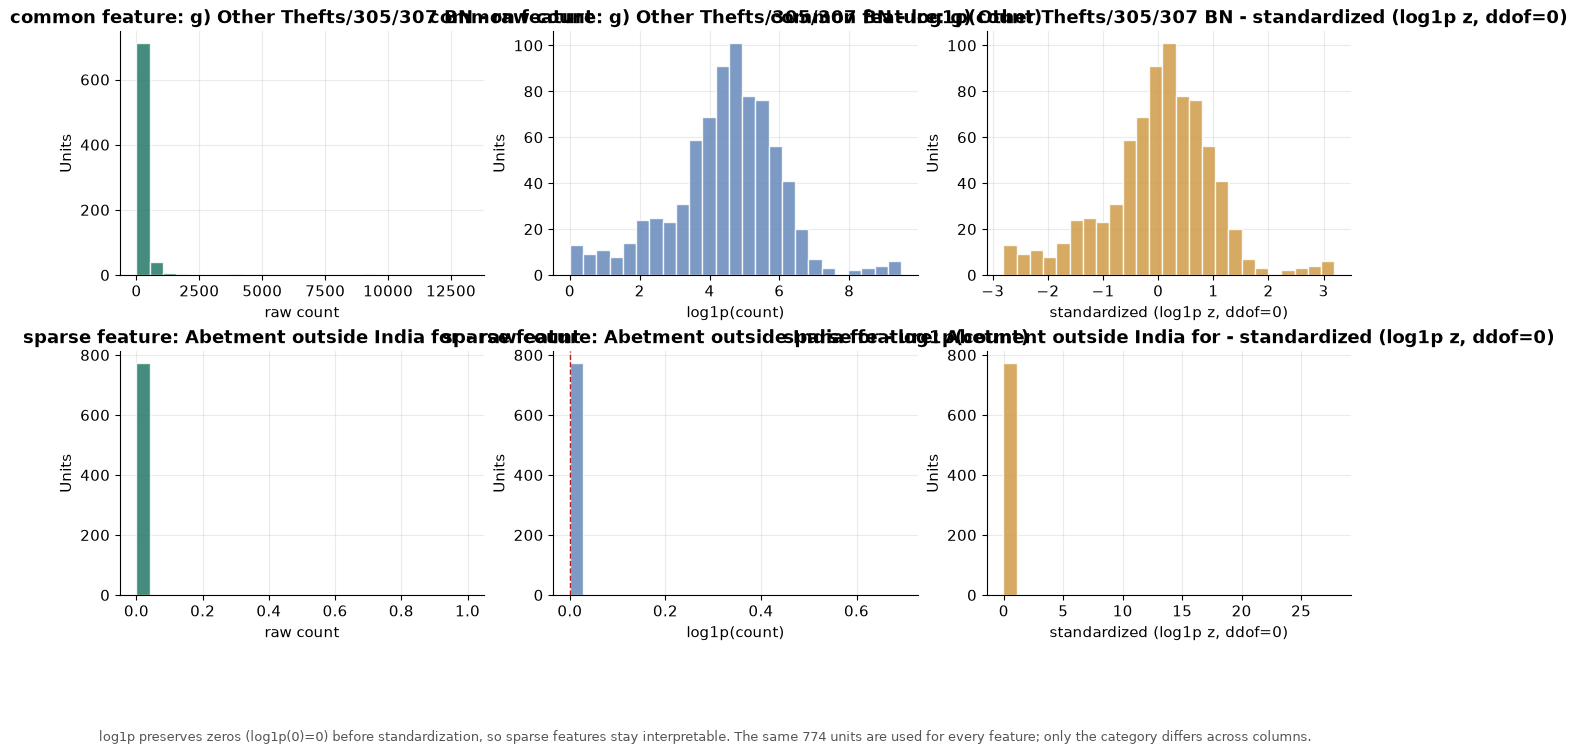

In [4]:

# Figure N03-02 · raw_log1p_and_standardized_feature_distributions
# One common and one sparse feature, shown raw / log1p / standardized side by side.
# Select a common feature (low zero fraction) and a sparse feature (high zero fraction).
cat_stats = features.groupby("category")["total"].apply(lambda s: (s == 0).mean()).sort_values()
common_feat = cat_stats.index[0]
sparse_feat = cat_stats.index[-1]

fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), constrained_layout=True)
titles = ["raw count", "log1p(count)", "standardized (log1p z, ddof=0)"]
for row, (feat_name, tag) in enumerate([(common_feat, "common"), (sparse_feat, "sparse")]):
    sub = features[features["category"] == feat_name].sort_values("region_name")
    vals = sub["total"].values
    logged = np.log1p(vals)
    std = (logged - logged.mean()) / (logged.std(ddof=0) or 1.0)
    for col, (arr, ttl) in enumerate(zip([vals, logged, std], titles)):
        ax = axes[row, col]
        ax.hist(arr, bins=25, color=SERIES[col], alpha=0.85, edgecolor="white")
        ax.set_xlabel(ttl)
        ax.set_ylabel("Units")
        ax.set_title(f"{tag} feature: {feat_name[:26]} - {ttl}")
        if row == 1 and col == 1:
            ax.axvline(0, color=RED, ls="--", lw=1)
fig_note(fig, "log1p preserves zeros (log1p(0)=0) before standardization, so sparse features stay interpretable. "
              "The same 774 units are used for every feature; only the category differs across columns.")
plt.show()


## log1p and feature-wise standardization

The active matrix uses `log1p(count)` followed by population-standard z-scoring (`ddof=0`) separately for each category across the 774 districts. This reduces the influence of very large raw counts while keeping zero explicit. The example below calls the project’s matrix builder and transformation helper on the saved feature input.

In [5]:
from crimescope_analysis.methods.pca import load_feature_matrix, build_matrix
from crimescope_analysis.features.matrix import vectors_from_matrix

feature_records = load_feature_matrix(feature_path)
matrix = build_matrix(feature_records, 2024, feature_mode="log1p_zscore")
vectors = np.asarray(vectors_from_matrix(matrix, "log1p_zscore"))
sample = features[(features["region_name"] == "Anantapuramu") & features["category"].str.contains("Murder BNS/Section 302 IPC", regex=False)].iloc[0]
region_index = next(i for i, region_key in enumerate(matrix["regions"]) if matrix["region_ids"].get(region_key) == sample["region_id"])
category_index = matrix["categories"].index(sample["category"])
raw_count = int(sample["total"])
transformed = float(vectors[region_index, category_index])
transformation = pd.DataFrame([{
    "district": f"{sample['state_name']} / {sample['region_name']}", "category": sample["category"],
    "reported cases x": raw_count, "log1p(x)": np.log1p(raw_count), "saved-cohort z-score": transformed,
    "cohort": "2024 eligible administrative districts"
}])
display(transformation)
assert vectors.shape == (774, 131)

,district,category,reported cases x,log1p(x),saved-cohort z-score,cohort
0,Andhra Pradesh / Anantapuramu,a) Murder BNS/Section 302 IPC),61,4.127134,1.017716,2024 eligible administrative districts


## PCA: saved scores and loadings

PCA was run on the standardized 2024 matrix. The saved artifact contains only two principal components, so the plot and variance percentages describe those two dimensions only. A **score** is a district’s coordinate on a component; a **loading** is a feature’s weight in that component.

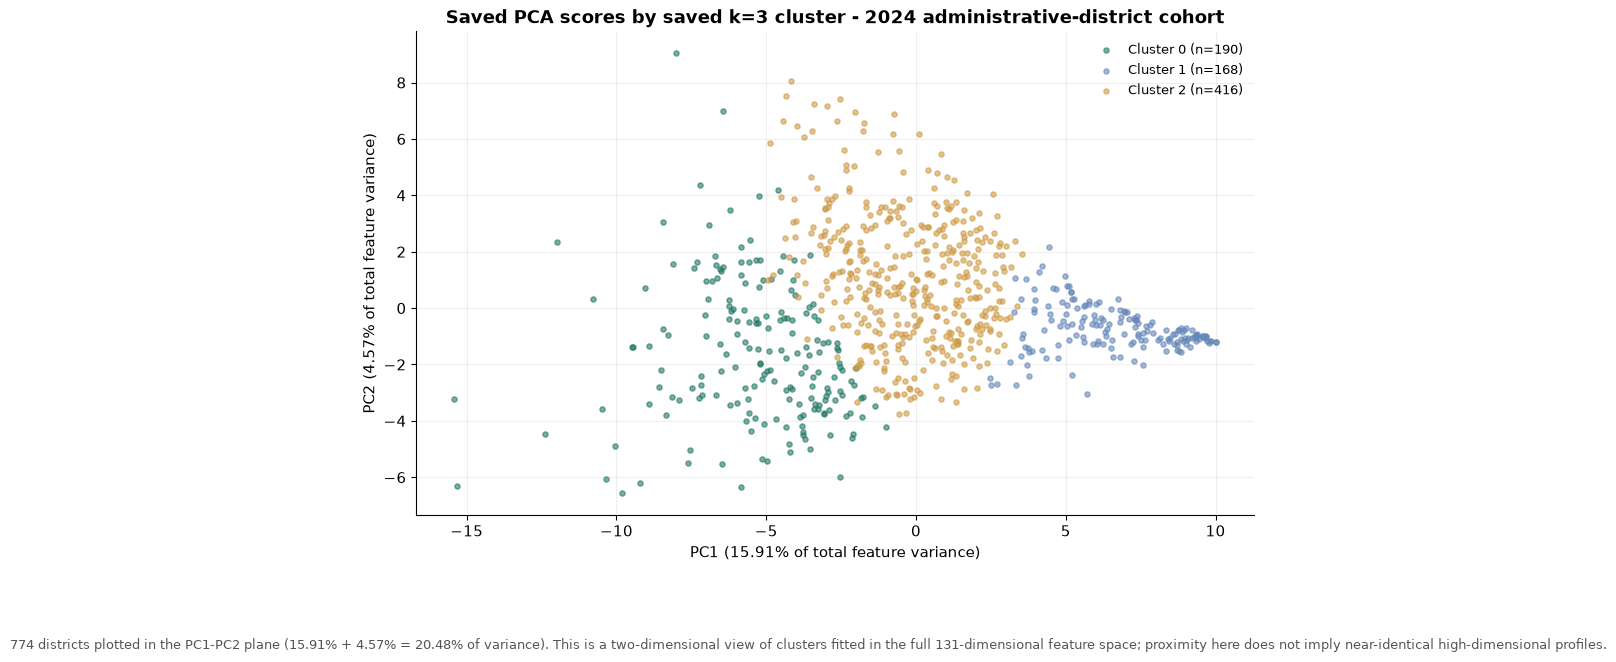

,component,feature,loading
0,PC1,b) Vehicle TheftBNS),-0.8544
1,PC1,g) Other Thefts/305/307 BNS/IPC),-0.8372
2,PC1,Cruelty by Husband or Relatives,-0.8096
3,PC1,a) Murder BNS/Section 302 IPC),-0.8041
4,PC1,"Robbery, 309, 311 BNS/Section 392/394/397 IPC)",-0.7947
5,PC2,Dowry Death,0.6487
6,PC2,"Kidnapping, abducting or inducing Women to com...",0.6001
7,PC2,Affray,-0.5200
8,PC2,a) Day Burglary,-0.5161
9,PC2,"Offences related to Mischief,326 BNS/Section 4...",-0.4834


In [6]:

# Figure N03-04 · pca_scores_by_k3_cluster_2024 (improved, replaces original scatter cell)
# Cell preserves the PCA setup, the improved scatter, and the saved loadings table.
pca_path = artifact(run["methods"]["pca"]["artifact"])
pca = json.loads(pca_path.read_text(encoding="utf-8"))
assert pca["n_regions"] == 774 and pca["n_categories"] == 131 and pca["n_components"] == 2
variance = [100 * x for x in pca["explained_variance_ratio"]]
assert np.allclose(variance, [15.910842, 4.574008], atol=.001)

score_rows = []
for row in pca["components"]:
    d = {item["component"]: item["score"] for item in row["scores"]}
    score_rows.append({"region_id": row["region_id"], "region label": row["region"], "PC1": d["PC1"], "PC2": d["PC2"]})
scores = pd.DataFrame(score_rows)
km3_preview = json.loads(artifact(run["methods"]["kmeans"]["artifacts"][0]).read_text(encoding="utf-8"))
cluster_map = {r["region_id"]: r["cluster_id"] for r in km3_preview["assignment_records"]}
scores["k=3 cluster"] = scores["region_id"].map(cluster_map)
assert scores[["PC1","PC2","k=3 cluster"]].notna().all().all()

fig, ax = plt.subplots(figsize=(9, 5.6), constrained_layout=True)
cluster_colors = {0: SERIES[0], 1: SERIES[1], 2: SERIES[2]}
for cluster_id, group in scores.groupby("k=3 cluster"):
    ax.scatter(group.PC1, group.PC2, s=14, alpha=0.6, label=f"Cluster {cluster_id} (n={len(group)})",
               color=cluster_colors.get(cluster_id, GREY))
ax.set_xlabel(f"PC1 ({variance[0]:.2f}% of total feature variance)")
ax.set_ylabel(f"PC2 ({variance[1]:.2f}% of total feature variance)")
ax.set_title("Saved PCA scores by saved k=3 cluster - 2024 administrative-district cohort")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
fig_note(fig, f"{len(scores)} districts plotted in the PC1-PC2 plane ({variance[0]:.2f}% + {variance[1]:.2f}% = {variance[0]+variance[1]:.2f}% of variance). "
              "This is a two-dimensional view of clusters fitted in the full 131-dimensional feature space; "
              "proximity here does not imply near-identical high-dimensional profiles.")
plt.show()

loading_rows = []
for component in pca["loadings"]:
    top = sorted(component["features"], key=lambda x: abs(x["loading"]), reverse=True)[:5]
    loading_rows.extend({"component": component["component"], "feature": item["category"], "loading": item["loading"]} for item in top)
display(pd.DataFrame(loading_rows).round({"loading": 4}))


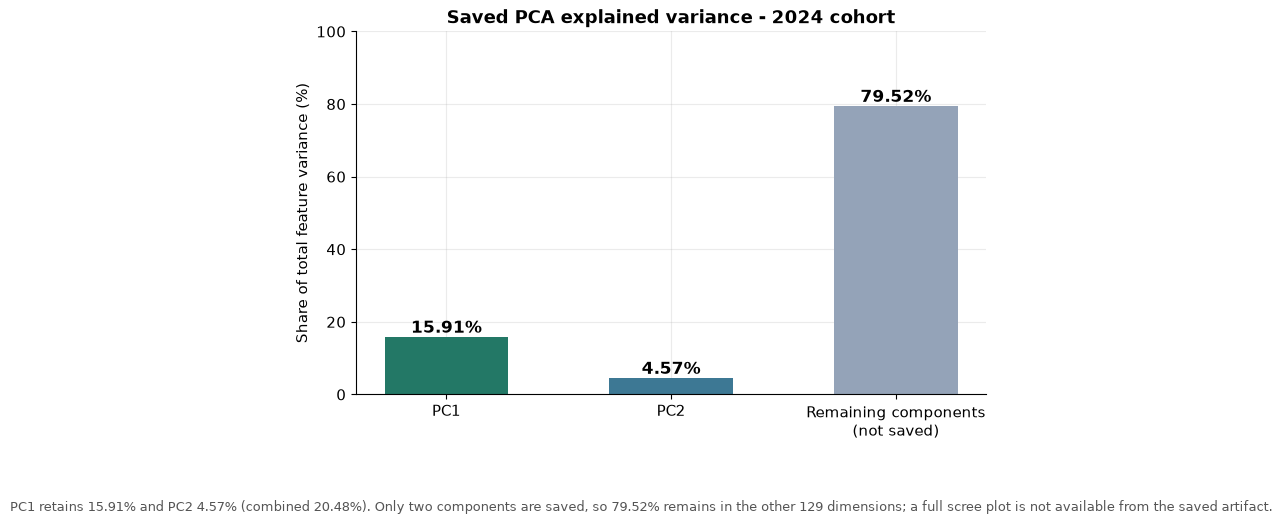

In [7]:

# Figure N03-03 · pca_explained_variance
# Variance shares actually present in the saved run (PC1, PC2 saved; full spectrum not available).
pc1, pc2 = variance[0], variance[1]
remaining = 100 - pc1 - pc2

fig, ax = plt.subplots(figsize=(7, 4.4), constrained_layout=True)
bars = ax.bar(["PC1", "PC2", "Remaining components\n(not saved)"], [pc1, pc2, remaining],
              color=[PRIMARY, BLUE, GREY], width=0.55)
for rect, v in zip(bars, [pc1, pc2, remaining]):
    ax.text(rect.get_x() + rect.get_width() / 2, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=12, fontweight="bold")
ax.set_ylabel("Share of total feature variance (%)")
ax.set_ylim(0, 100)
ax.set_title("Saved PCA explained variance - 2024 cohort")
fig_note(fig, f"PC1 retains {pc1:.2f}% and PC2 {pc2:.2f}% (combined {pc1+pc2:.2f}%). Only two components are "
              f"saved, so {remaining:.2f}% remains in the other 129 dimensions; a full scree plot is not available from the saved artifact.")
plt.show()


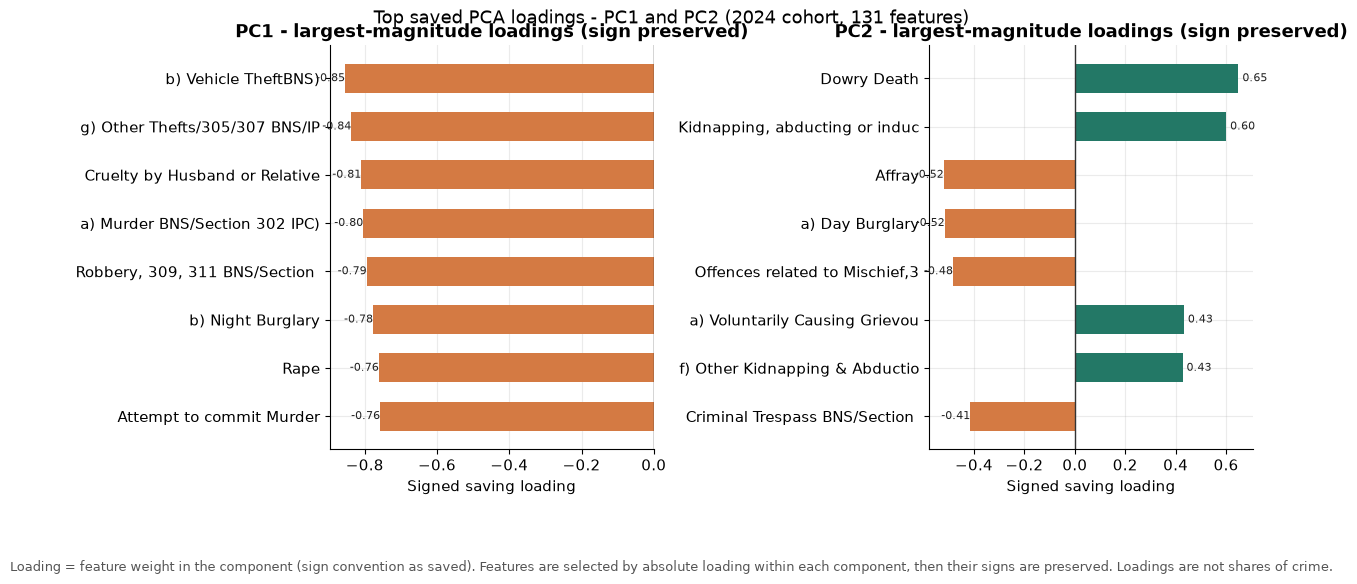

In [8]:

# Figure N03-06 · pca_top_feature_loadings
# Largest positive and negative saved loadings for PC1 and PC2 (two panels).
def top_loadings(comp, n=8):
    feats = [f for f in pca["loadings"] if f["component"] == comp][0]["features"]
    return sorted(feats, key=lambda x: abs(x["loading"]), reverse=True)[:n]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, comp in zip(axes, ["PC1", "PC2"]):
    feats = top_loadings(comp)
    names = [f["category"][:30] for f in feats][::-1]
    vals = [f["loading"] for f in feats][::-1]
    cols = [PRIMARY if v >= 0 else ACCENT for v in vals]
    ax.barh(names, vals, color=cols, height=0.6)
    ax.axvline(0, color="#333", lw=1)
    ax.set_xlabel("Signed saving loading")
    ax.set_title(f"{comp} - largest-magnitude loadings (sign preserved)")
    for i, (nme, v) in enumerate(zip(names, vals)):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=8,
                ha="left" if v >= 0 else "right", color="#222")
fig.suptitle("Top saved PCA loadings - PC1 and PC2 (2024 cohort, 131 features)", fontsize=13, y=1.02)
fig_note(fig, "Loading = feature weight in the component (sign convention as saved). Features are selected by "
              "absolute loading within each component, then their signs are preserved. Loadings are not shares of crime.")
plt.show()


### PC1 and the official reported total

Join saved PC1 scores to the 2024 official-total observation by stable `geography_id`, then correlate PC1 with `log1p(official reported total)`. This checks whether the component is associated with reporting volume; the sign of a PCA axis can be reversed without changing the model.

In [9]:
official_total = next(c for c in taxonomy["categories"] if 2024 in c["years"] and "official_total" in c["rolesByYear"].get("2024", []))
totals = pd.read_sql_query("""SELECT geography_id AS region_id,reported_value AS official_total
    FROM crime_observations WHERE year=2024 AND region_type='administrative_district'
      AND quality_status='valid' AND comparison_status='eligible' AND category_id=?""", db, params=(official_total["id"],))
joined = scores.merge(totals, on="region_id", how="inner", validate="one_to_one")
joined["log1p official total"] = np.log1p(joined["official_total"])
pc1_total_corr = joined[["PC1","log1p official total"]].corr().iloc[0,1]
print(f"Joined cohort: {len(joined)} districts | Pearson correlation(PC1, log1p official total) = {pc1_total_corr:.4f}")
assert len(joined) == 774 and np.isclose(pc1_total_corr, -0.877393, atol=.00001)

Joined cohort: 774 districts | Pearson correlation(PC1, log1p official total) = -0.8774


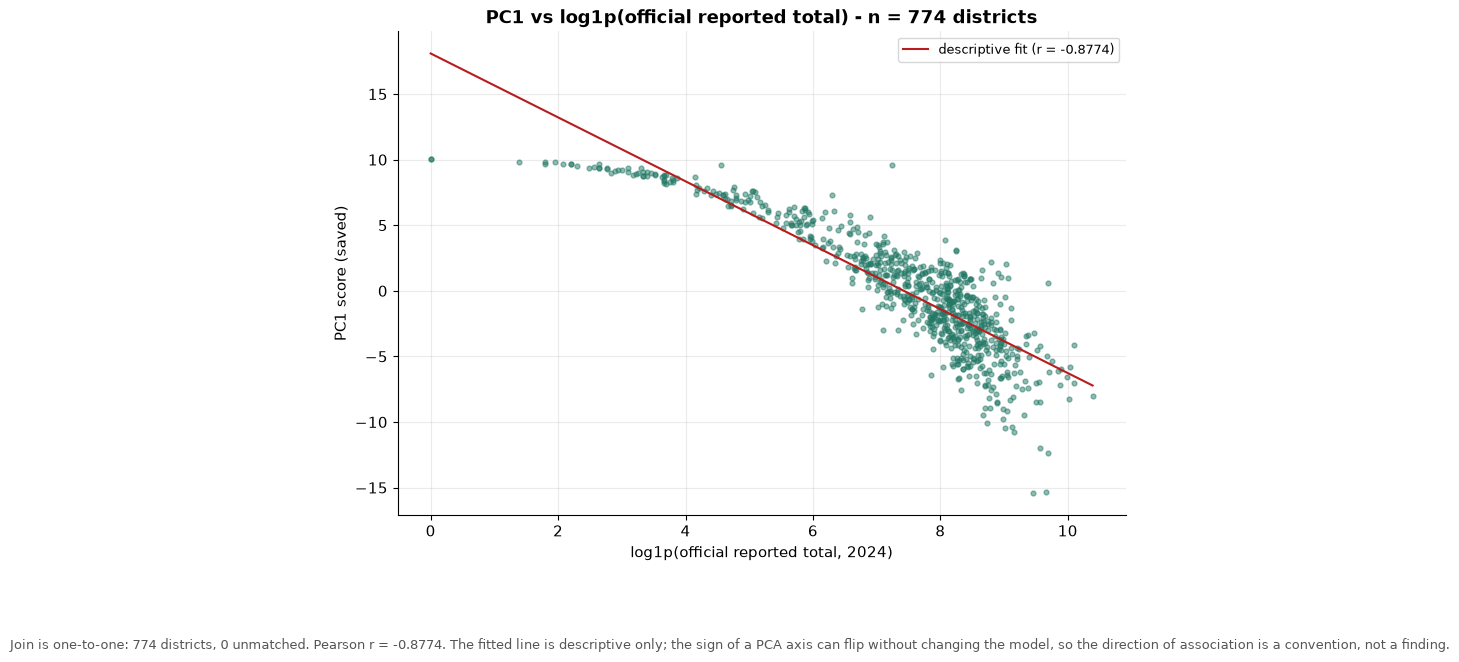

In [10]:

# Figure N03-05 · pc1_vs_log_reported_total_2024
# Saved PC1 vs log1p(official reported total), one-to-one join, with correlation.
joined_sorted = joined.sort_values("log1p official total")
fig, ax = plt.subplots(figsize=(8, 5.6), constrained_layout=True)
ax.scatter(joined["log1p official total"], joined["PC1"], s=12, alpha=0.5, color=PRIMARY)
m, b = np.polyfit(joined["log1p official total"], joined["PC1"], 1)
xx = np.linspace(joined["log1p official total"].min(), joined["log1p official total"].max(), 50)
ax.plot(xx, m * xx + b, color=RED, lw=1.5, label=f"descriptive fit (r = {pc1_total_corr:.4f})")
ax.set_xlabel("log1p(official reported total, 2024)")
ax.set_ylabel("PC1 score (saved)")
ax.set_title(f"PC1 vs log1p(official reported total) - n = {len(joined)} districts")
ax.legend(fontsize=9)
fig_note(fig, f"Join is one-to-one: {len(joined)} districts, 0 unmatched. Pearson r = {pc1_total_corr:.4f}. "
              "The fitted line is descriptive only; the sign of a PCA axis can flip without changing the model, "
              "so the direction of association is a convention, not a finding.")
plt.show()


## K-means: saved k=3, 4, and 5 results

Inertia is the sum of squared distances from districts to their assigned centroid in the transformed feature space. It tends to fall as `k` increases, so these values alone do not select an optimal cluster count. The notebook reads saved assignments and centroids only.

In [11]:
kmeans_rows = []
kmeans_artifacts = run["methods"]["kmeans"]["artifacts"]
kmeans_saved = {}
for relative in kmeans_artifacts:
    model = json.loads(artifact(relative).read_text(encoding="utf-8"))
    kmeans_saved[model["k"]] = model
    sizes = pd.Series([x["cluster_id"] for x in model["assignment_records"]]).value_counts().sort_index()
    kmeans_rows.append({"k": model["k"], "districts": model["n_regions"], "features": model["n_categories"],
                        "inertia": model["inertia"], "cluster sizes": dict(sizes)})
display(pd.DataFrame(kmeans_rows))
assert sorted(kmeans_saved) == [3,4,5]
cluster3 = kmeans_saved[3]
chosen_cluster = max(cluster3["clusters"], key=lambda c: c["size"])
centroid_profile = sorted(chosen_cluster["centroid"].items(), key=lambda kv: kv[1], reverse=True)[:6]
print(f"Saved k=3 descriptive profile: cluster {chosen_cluster['cluster_id']} has {chosen_cluster['size']} districts.")
display(pd.DataFrame([{"category": cat, "cluster centroid (standardized log count)": value} for cat,value in centroid_profile]).round(4))

,k,districts,features,inertia,cluster sizes
0,3,774,131,86824.917445,"{0: 190, 1: 168, 2: 416}"
1,4,774,131,85963.964527,"{0: 4, 1: 168, 2: 405, 3: 197}"
2,5,774,131,83473.810905,"{0: 4, 1: 167, 2: 372, 3: 192, 4: 39}"


Saved k=3 descriptive profile: cluster 2 has 416 districts.


,category,cluster centroid (standardized log count)
0,a) Voluntarily Causing Grievous Hurt BNS/Secti...,0.3399
1,a) Murder BNS/Section 302 IPC),0.3279
2,Other IPC/BNS crimes,0.2974
3,Dowry Death,0.2835
4,Attempt to commit Murder,0.2712
5,"Kidnapping, abducting or inducing Women to com...",0.2634


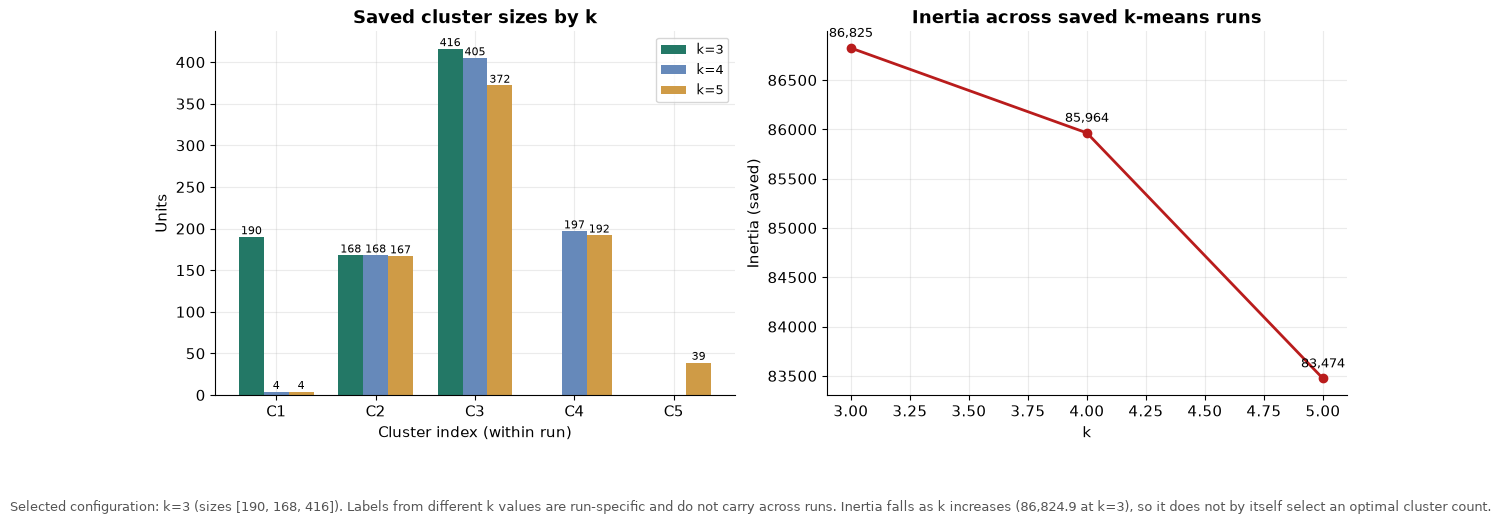

In [12]:

# Figure N03-07 · kmeans_cluster_sizes_and_inertia
# Cluster sizes for k=3,4,5 and inertia across saved runs.
ks = sorted(kmeans_saved.keys())
sizes = [kmeans_saved[k]["cluster_sizes"] for k in ks]
inertias = [kmeans_saved[k]["inertia"] for k in ks]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for i, k in enumerate(ks):
    sz = sizes[i]
    x = np.arange(len(sz)) + i * 0.25
    axes[0].bar(x, sz, width=0.25, label=f"k={k}", color=SERIES[i % len(SERIES)])
    for xi, v in zip(x, sz):
        axes[0].text(xi, v, str(v), ha="center", va="bottom", fontsize=8)
axes[0].set_xlabel("Cluster index (within run)")
axes[0].set_ylabel("Units")
axes[0].set_title("Saved cluster sizes by k")
axes[0].set_xticks(np.arange(max(len(s) for s in sizes)) + 0.25)
axes[0].set_xticklabels([f"C{j+1}" for j in range(max(len(s) for s in sizes))])
axes[0].legend(fontsize=9)
axes[1].plot(ks, inertias, marker="o", color=RED, lw=2)
for k, v in zip(ks, inertias):
    axes[1].annotate(f"{v:,.0f}", (k, v), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
axes[1].set_xlabel("k")
axes[1].set_ylabel("Inertia (saved)")
axes[1].set_title("Inertia across saved k-means runs")
fig_note(fig, f"Selected configuration: k=3 (sizes {kmeans_saved[3]['cluster_sizes']}). Labels from different k values "
              f"are run-specific and do not carry across runs. Inertia falls as k increases (86,824.9 at k=3), "
              "so it does not by itself select an optimal cluster count.")
plt.show()


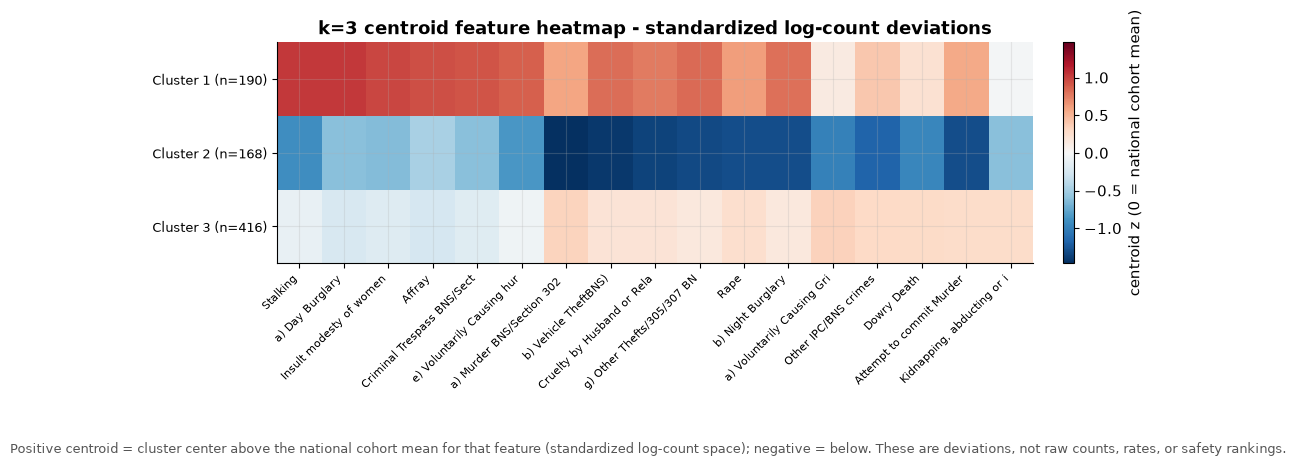

In [13]:

# Figure N03-08 · k3_centroid_feature_heatmap
# Standardized centroid values for deterministically selected distinguishing features, k=3.
km3 = kmeans_saved[3]
centroids = {c["cluster_id"]: c["centroid"] for c in km3["clusters"]}
# deterministically select top-|centroid| features union across clusters
picked = []
for cid in range(3):
    top = sorted(centroids[cid].items(), key=lambda kv: abs(kv[1]), reverse=True)[:6]
    for name, _ in top:
        if name not in picked:
            picked.append(name)
mat = np.array([[centroids[cid].get(f, 0.0) for f in picked] for cid in range(3)], dtype=float)
vmax = float(np.max(np.abs(mat))) or 1.0

fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
im = ax.imshow(mat, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.set_yticks(range(3))
ax.set_yticklabels([f"Cluster {cid+1} (n={km3['cluster_sizes'][cid]})" for cid in range(3)], fontsize=9)
ax.set_xticks(range(len(picked)))
ax.set_xticklabels([p[:26] for p in picked], rotation=45, ha="right", fontsize=8)
ax.set_title("k=3 centroid feature heatmap - standardized log-count deviations")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("centroid z (0 = national cohort mean)")
fig_note(fig, "Positive centroid = cluster center above the national cohort mean for that feature (standardized "
              "log-count space); negative = below. These are deviations, not raw counts, rates, or safety rankings.")
plt.show()


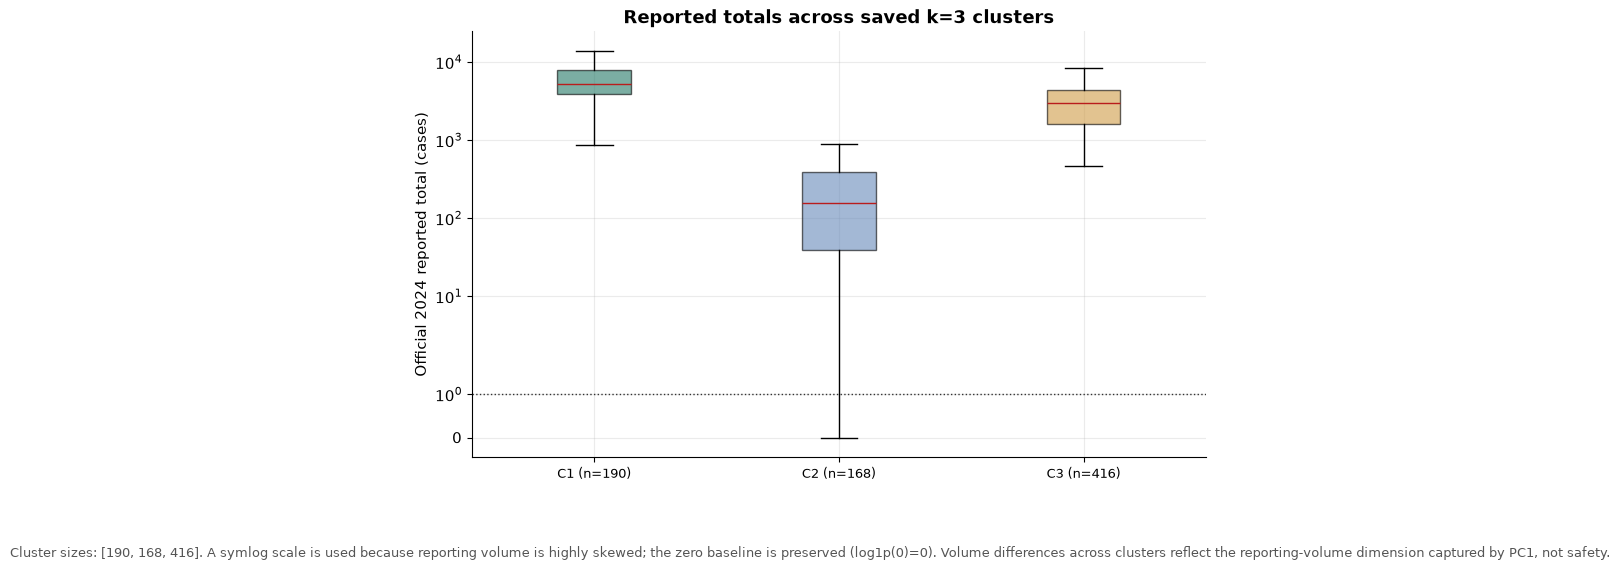

In [14]:

# Figure N03-09 · k3_reported_totals_by_cluster
# Box plots of official reported totals across the three saved k=3 clusters.
ot_id = db.execute("""SELECT category_id FROM crime_observations WHERE year=2024 AND original_category='Total Cognizable IPC/BNS crimes' LIMIT 1""").fetchone()[0]
totals_map = {r[0]: r[1] for r in db.execute("""SELECT geography_id, reported_value FROM crime_observations
    WHERE year=2024 AND region_type='administrative_district' AND quality_status='valid'
      AND comparison_status='eligible' AND category_id=?""", (ot_id,))}
assign = {r["region_id"]: r["cluster_id"] for r in km3["assignment_records"]}
cluster_vals = {cid: [totals_map[rid] for rid, c in assign.items() if c == cid and rid in totals_map] for cid in range(3)}
order = [cluster_vals[cid] for cid in range(3)]

fig, ax = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
bp = ax.boxplot(order, patch_artist=True, showfliers=False, medianprops={"color": RED})
for patch, col in zip(bp["boxes"], SERIES[:3]):
    patch.set_facecolor(col); patch.set_alpha(0.6)
ax.set_ylabel("Official 2024 reported total (cases)")
ax.set_title("Reported totals across saved k=3 clusters")
ax.set_xticklabels([f"C{cid+1} (n={len(cluster_vals[cid])})" for cid in range(3)], fontsize=9)
ax.set_yscale("symlog")
ax.axhline(1, color="#333", ls=":", lw=1)
fig_note(fig, f"Cluster sizes: {[km3['cluster_sizes'][cid] for cid in range(3)]}. A symlog scale is used because "
              "reporting volume is highly skewed; the zero baseline is preserved (log1p(0)=0). Volume differences "
              "across clusters reflect the reporting-volume dimension captured by PC1, not safety.")
plt.show()


The centroid values above are standardized log-count coordinates: positive values mean that cluster’s center lies above the national cohort mean for that feature. They are not per-capita rates, severity scores, or a ranking of districts.

## A saved Ward example: Andhra Pradesh

The active runner fits Ward separately inside each state/UT, using that state’s own district subset and the same `log1p_zscore` transformation. The saved merge history stops when three clusters remain, so it is not a complete dendrogram; show the final merge steps and memberships instead.

In [15]:
ward_relative = run["methods"]["hierarchical"]["artifacts_by_state"]["Andhra Pradesh"]
ward = json.loads(artifact(ward_relative).read_text(encoding="utf-8"))
assert ward["linkage"] == "ward" and ward["feature_mode"] == "log1p_zscore"
assert ward["n_regions"] == 26 and ward["n_categories"] == 131 and len(ward["merge_history"]) == 23
region_names = features.drop_duplicates("region_id").set_index("region_id")[["state_name", "region_name"]]
ward_memberships = pd.DataFrame([{"cluster": c["cluster_id"], "district count": c["size"], "members": ", ".join(f"{region_names.loc[rid, 'state_name']} / {region_names.loc[rid, 'region_name']}" for rid in c["region_ids"])} for c in ward["clusters"]])
display(ward_memberships)
display(pd.DataFrame(ward["merge_history"][-5:]))

,cluster,district count,members
0,0,6,"Andhra Pradesh / West Godavari, Andhra Pradesh..."
1,1,8,"Andhra Pradesh / Kurnool, Andhra Pradesh / Eas..."
2,2,12,"Andhra Pradesh / Alluri Sitharama Raju, Andhra..."


,clusters_merged,distance,new_cluster_size,remaining_clusters
0,"[0, 1]",382.418360,4,7
1,"[0, 1]",520.804086,6,6
2,"[0, 1]",568.467242,8,5
3,"[0, 1]",868.426111,8,4
4,"[0, 2]",1153.815949,12,3


### Interpretation and limitations

The active matrix contains 774 administrative reporting units by 131 category features and is based on 2024 BNS reported counts. PCA’s saved two-component view retains 20.48% of total feature variance. PC1 is strongly associated with the log official total in this cohort, which is consistent with a reporting-volume dimension. K-means memberships summarize similarity under the stated transform; they do not identify causal types or objectively best clusters. Ward memberships are state-specific and should not be compared across states as one national clustering.

## Appendix: additional PCA and clustering diagnostics

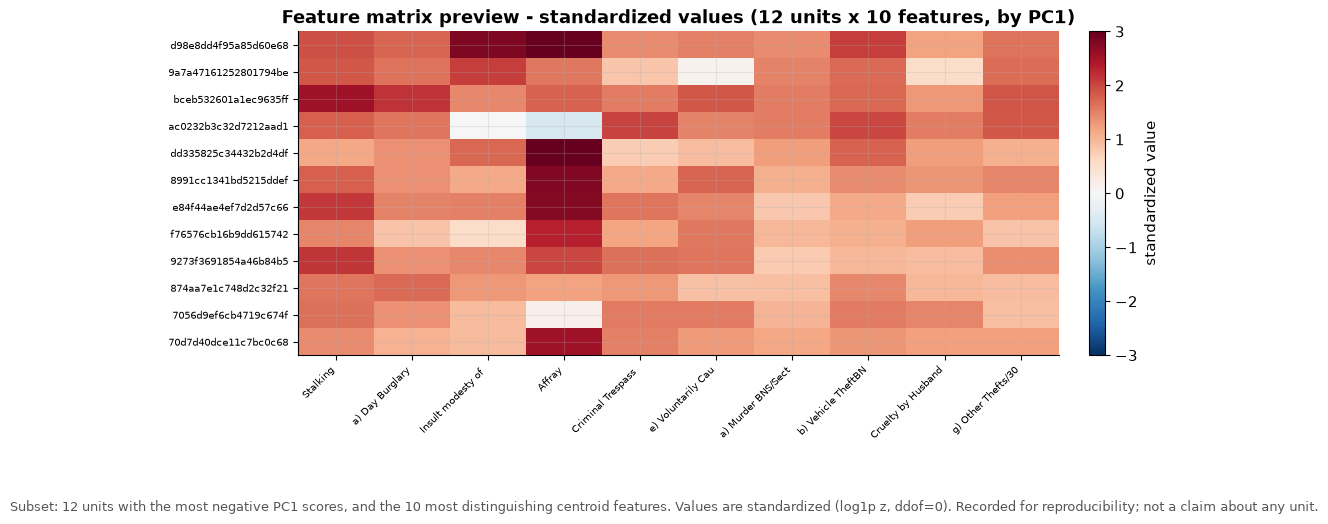

In [16]:

# Figure N03-10 · feature_matrix_preview (optional)
# Heatmap of a deterministic subset of units and features (standardized values).
subset_regions = scores.sort_values("PC1").head(12)["region_id"].tolist()
subset_feats = picked[:10]
ridx = {r: i for i, r in enumerate(matrix["regions"])}
fidx = {f: i for i, f in enumerate(matrix["categories"])}
pre = np.zeros((len(subset_regions), len(subset_feats)))
for i, rid in enumerate(subset_regions):
    for j, f in enumerate(subset_feats):
        if rid in ridx and f in fidx:
            pre[i, j] = vectors[ridx[rid], fidx[f]]
fig, ax = plt.subplots(figsize=(10, 4.4), constrained_layout=True)
im = ax.imshow(pre, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
ax.set_yticks(range(len(subset_regions)))
ax.set_yticklabels([f"{r[:20]}" for r in subset_regions], fontsize=7)
ax.set_xticks(range(len(subset_feats)))
ax.set_xticklabels([f[:18] for f in subset_feats], rotation=45, ha="right", fontsize=7)
ax.set_title("Feature matrix preview - standardized values (12 units x 10 features, by PC1)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("standardized value")
fig_note(fig, "Subset: 12 units with the most negative PC1 scores, and the 10 most distinguishing centroid features. "
              "Values are standardized (log1p z, ddof=0). Recorded for reproducibility; not a claim about any unit.")
plt.show()


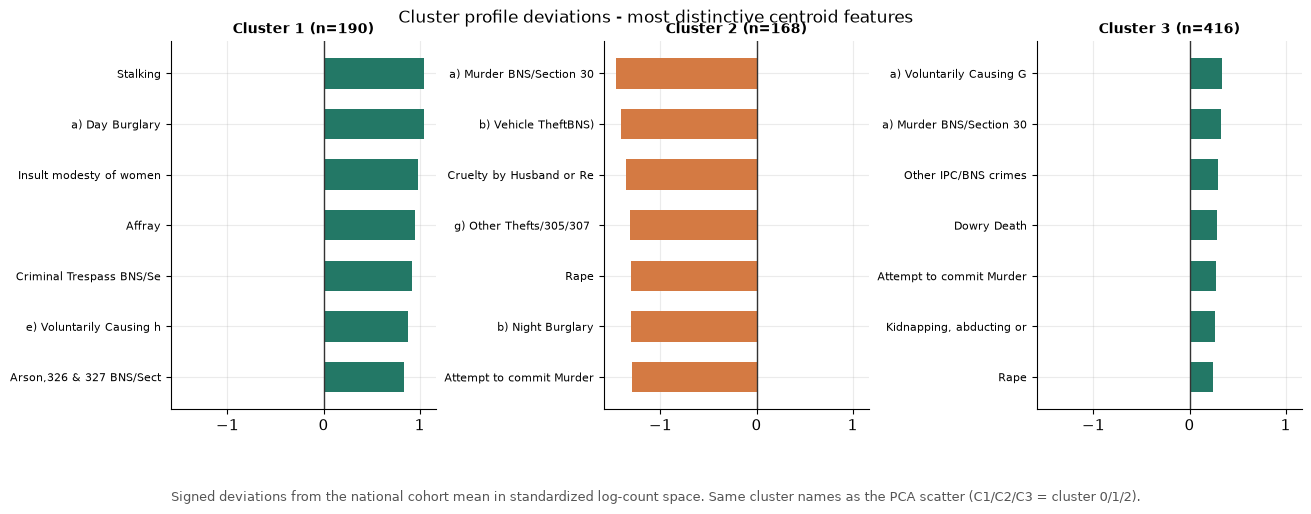

In [17]:

# Figure N03-11 · cluster_profile_deviations (optional)
# Horizontal signed bars of most distinctive centroid features per k=3 cluster.
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), constrained_layout=True, sharex=True)
for ax, cid in zip(axes, range(3)):
    top = sorted(centroids[cid].items(), key=lambda kv: abs(kv[1]), reverse=True)[:7]
    names = [n[:24] for n, _ in top][::-1]
    vals = [v for _, v in top][::-1]
    ax.barh(names, vals, color=[PRIMARY if v >= 0 else ACCENT for v in vals], height=0.6)
    ax.axvline(0, color="#333", lw=1)
    ax.set_title(f"Cluster {cid+1} (n={km3['cluster_sizes'][cid]})", fontsize=10)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Cluster profile deviations - most distinctive centroid features", fontsize=12, y=1.02)
fig_note(fig, "Signed deviations from the national cohort mean in standardized log-count space. Same cluster names "
              "as the PCA scatter (C1/C2/C3 = cluster 0/1/2).")
plt.show()


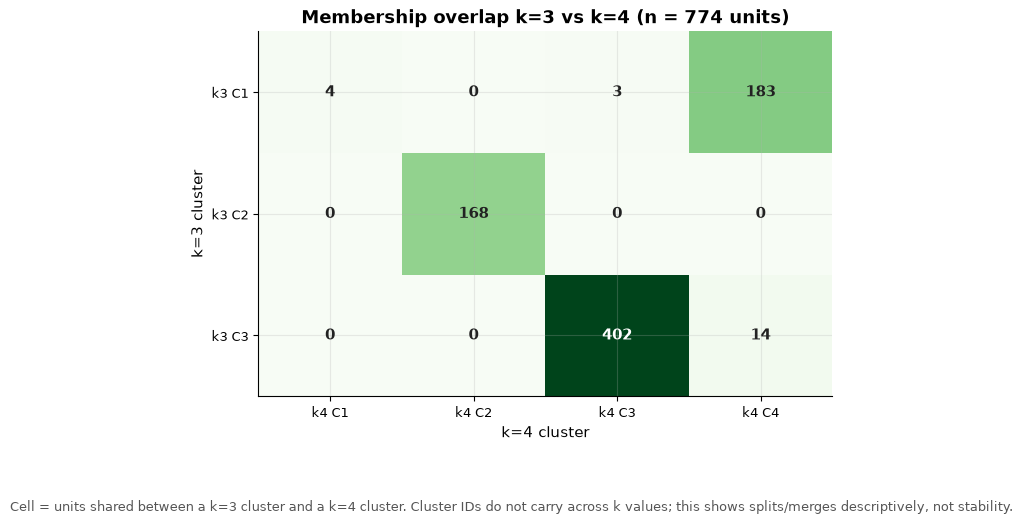

In [18]:

# Figure N03-12 · cluster_membership_overlap_across_k (optional)
# Overlap heatmap between saved k=3 and k=4 assignments.
km4 = kmeans_saved[4]
a3 = {r["region_id"]: r["cluster_id"] for r in km3["assignment_records"]}
a4 = {r["region_id"]: r["cluster_id"] for r in km4["assignment_records"]}
units = sorted(set(a3) & set(a4))
ov = np.zeros((3, 4), dtype=int)
for u in units:
    ov[a3[u], a4[u]] += 1
fig, ax = plt.subplots(figsize=(6.5, 4.4), constrained_layout=True)
im = ax.imshow(ov, aspect="auto", cmap="Greens")
for i in range(3):
    for j in range(4):
        ax.text(j, i, str(ov[i, j]), ha="center", va="center", fontsize=11, fontweight="bold",
                color="white" if ov[i, j] > ov.max() / 2 else "#222")
ax.set_xticks(range(4)); ax.set_xticklabels([f"k4 C{j+1}" for j in range(4)], fontsize=9)
ax.set_yticks(range(3)); ax.set_yticklabels([f"k3 C{i+1}" for i in range(3)], fontsize=9)
ax.set_xlabel("k=4 cluster"); ax.set_ylabel("k=3 cluster")
ax.set_title(f"Membership overlap k=3 vs k=4 (n = {len(units)} units)")
fig_note(fig, "Cell = units shared between a k=3 cluster and a k=4 cluster. Cluster IDs do not carry across k values; "
              "this shows splits/merges descriptively, not stability.")
plt.show()


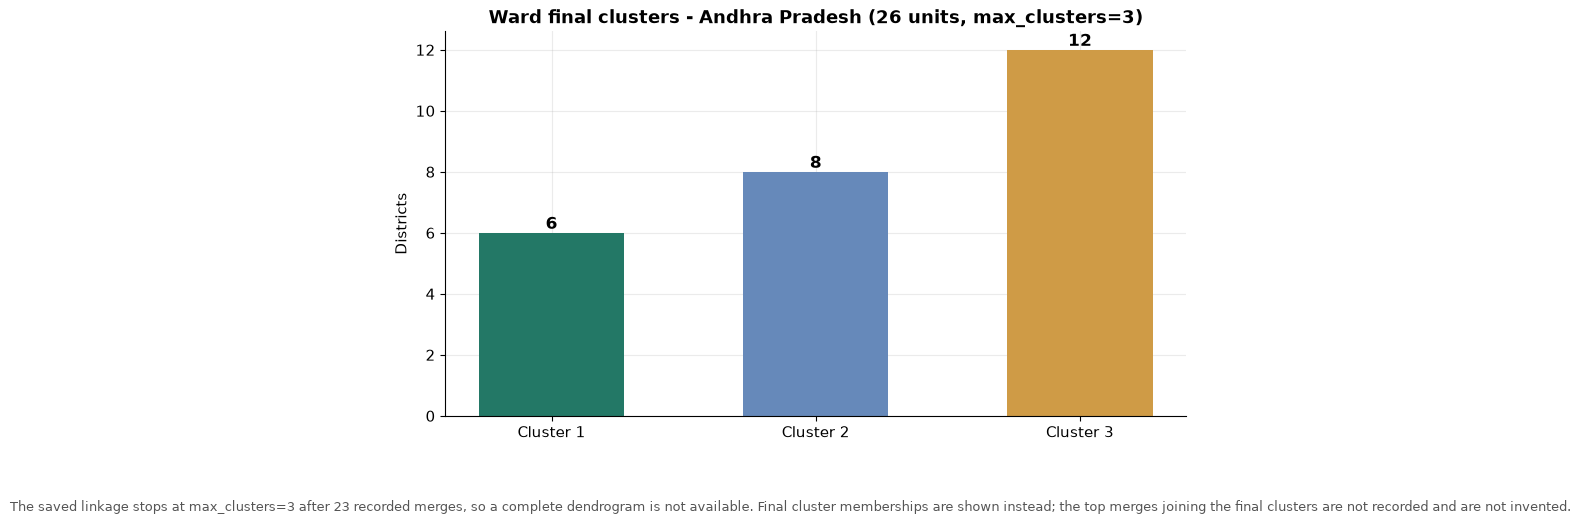

In [19]:

# Figure N03-13 · ward_hierarchical_state_example (optional)
# Andhra Pradesh Ward: final cluster memberships (complete linkage tree not recorded).
fig, ax = plt.subplots(figsize=(8, 4.4), constrained_layout=True)
sizes = [c["size"] for c in ward["clusters"]]
ids = [c["cluster_id"] for c in ward["clusters"]]
bars = ax.bar([f"Cluster {i+1}" for i in ids], sizes, color=SERIES[:len(ids)], width=0.55)
for rect, v in zip(bars, sizes):
    ax.text(rect.get_x() + rect.get_width() / 2, v, str(v), ha="center", va="bottom", fontsize=12, fontweight="bold")
ax.set_ylabel("Districts")
ax.set_title(f"Ward final clusters - Andhra Pradesh ({ward['n_regions']} units, max_clusters={ward['max_clusters']})")
fig_note(fig, f"The saved linkage stops at max_clusters={ward['max_clusters']} after {len(ward['merge_history'])} recorded merges, "
              "so a complete dendrogram is not available. Final cluster memberships are shown instead; the top merges "
              "joining the final clusters are not recorded and are not invented.")
plt.show()


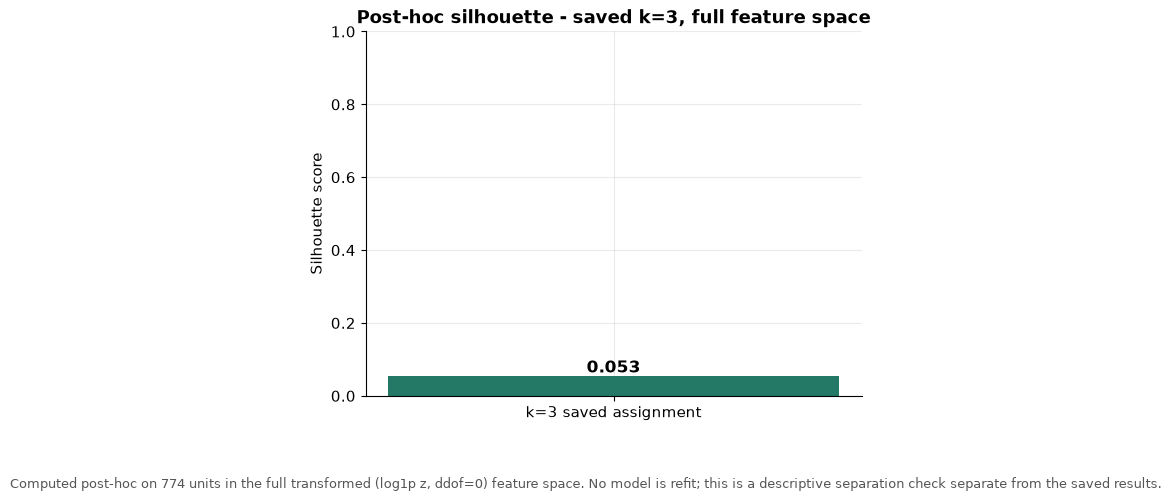

In [20]:

# Figure N03-14 · cluster_separation_diagnostic (optional, clearly labelled post-hoc)
# Silhouette scores for saved k=3 assignments in the full transformed feature space (no refit).
from sklearn.metrics import silhouette_score
labels = np.array([a3[u] for u in units])
try:
    sil = silhouette_score(vectors[np.array([ridx[u] for u in units])], labels)
    fig, ax = plt.subplots(figsize=(5.6, 4.2), constrained_layout=True)
    ax.bar(["k=3 saved assignment"], [sil], color=PRIMARY, width=0.4)
    ax.text(0, sil, f"{sil:.3f}", ha="center", va="bottom", fontsize=12, fontweight="bold")
    ax.set_ylabel("Silhouette score")
    ax.set_ylim(0, 1)
    ax.set_title("Post-hoc silhouette - saved k=3, full feature space")
    fig_note(fig, f"Computed post-hoc on {len(units)} units in the full transformed (log1p z, ddof=0) feature space. "
                  "No model is refit; this is a descriptive separation check separate from the saved results.")
    plt.show()
except Exception as e:
    print("Silhouette diagnostic skipped:", e)
